# CS4085 Deep Learning — Lab 5
## CNN Applications with TensorFlow Keras: Smile Detection and Sign-Language Digits

**Instructor:** Dr. Naila Marir
**Student:** Ahmad Balubaid  ·  **Student ID:** S23108476  ·  **Date:** 28 October 2026
**Course:** CS4085 Deep Learning · College of Engineering · Effat University
**Chapter:** Convolutional Neural Networks (applied lab)

---

### What you will do in this lab

1. **Part A:** Build a **binary** CNN that decides whether a person is **smiling or not**, using the Keras **Sequential API**.
2. **Part B:** Build a **multiclass** CNN that recognises **hand-sign digits 0–9**, using the Keras **Functional API**.
3. Train, evaluate, and **analyse** your models: learning curves, wrong predictions, and a confusion matrix.
4. **Challenge:** Improve the sign-digit model and compare it with the baseline.

### Learning outcomes

By the end of this lab you will be able to:

1. Build a CNN with the **Sequential API** and with the **Functional API**, and explain when to use each.
2. Choose the correct **output layer and loss** for binary vs multiclass problems.
3. Compute **output shapes and parameter counts** of CNN layers by hand.
4. Train with a **validation set**, read learning curves, and use **early stopping**.
5. Evaluate a classifier beyond accuracy (wrong predictions, confusion matrix).

## Table of Contents

0. [Why do we use a deep learning framework?](#0)
1. [Setup](#1)
2. [Part A — Smile Detector (Sequential API)](#2)
    - Exercise 1 — `happy_model`
    - Exercise 2 — Predictions and wrong cases
3. [Part B — Sign-Language Digits (Functional API)](#3)
    - Exercise 3 — `sign_model`
    - Exercise 4 — Confusion matrix
    - Exercise 5 — Challenge: improve the model
    - Exploration — five designs compared
4. [Sequential vs Functional — summary](#4)
5. [Reflection questions](#5)
6. [References](#6)

<a name='0'></a>
## 0 — Why do we use a deep learning framework?

Imagine you want to build an AI system that recognises **cats and dogs** in images.

You already know how neural networks work: forward propagation, backpropagation, gradient descent, and weight updates.

**Question:** does that mean you should program every operation yourself?

Not necessarily. This short section explains why, using small code examples you can run.

### 0.1 Why did we first build networks from scratch?

In Labs 1–4 we used **Python and NumPy** to write forward propagation, the loss, backpropagation and gradient descent ourselves.

We did this to **understand what happens inside the network**. For example, one layer computes:

$$z = Wx + b \qquad a = \text{ReLU}(z)$$

Run the cell below: this is one layer written **by hand**.

In [1]:
import time
import numpy as np
import tensorflow as tf

np.random.seed(0)
x = np.random.randn(10, 1)          # 10 input features
W = np.random.randn(5, 10) * 0.1    # we create the weights ourselves
b = np.zeros((5, 1))                # we create the bias ourselves

z = W @ x + b                       # linear step
a = np.maximum(0, z)                # ReLU
print("Output of the layer (by hand):", a.ravel().round(3))

Output of the layer (by hand): [0.342 0.112 0.    0.    0.   ]


### 0.2 What is the problem with building everything from scratch?

Now imagine a **large CNN for medical image classification**, with millions of parameters and many layers. By hand, you must write convolutions, activations, gradients, parameter updates, GPU code, and more.

This creates three problems:

1. **It takes too much time.** We spend more time on basic operations than on our AI solution.
2. **It is hard to maintain.** Large hand-written code becomes complex and buggy.
3. **It can be slow.** Our code is usually slower than highly optimised libraries.

### 0.3 Andrew Ng's analogy: matrix multiplication

You know how to multiply two matrices, and you could write the loops yourself.

But if your program does **millions** of multiplications, you would use a library such as NumPy: `np.matmul(A, B)`.

Run the cell to compare our own loops with NumPy on the **same** calculation.

In [2]:
def my_matmul(A, B):
    # Matrix multiplication written by hand with three loops
    n, k = A.shape
    _, m = B.shape
    C = np.zeros((n, m))
    for i in range(n):
        for j in range(m):
            for t in range(k):
                C[i, j] += A[i, t] * B[t, j]
    return C

A = np.random.randn(100, 100)
B = np.random.randn(100, 100)

t0 = time.time(); C1 = my_matmul(A, B); t_loops = time.time() - t0
t0 = time.time(); C2 = np.matmul(A, B); t_numpy = time.time() - t0

print("Same result?      ", np.allclose(C1, C2))
print(f"Our loops:          {t_loops:.4f} s")
print(f"NumPy np.matmul:    {t_numpy:.6f} s")
print(f"NumPy is about {t_loops / max(t_numpy, 1e-9):,.0f} times faster")

Same result?       True
Our loops:          0.4491 s
NumPy np.matmul:    0.002999 s
NumPy is about 150 times faster


**Key idea:** you still *understand* matrix multiplication, but you let a library *execute* it efficiently.

Deep learning frameworks follow exactly the same principle for neural networks.

### 0.4 What is a deep learning framework?

A **deep learning framework** is a software library with ready-made tools to **build, train and deploy** neural networks. Think of it as a box of **building blocks**.

| From scratch (Labs 1–4) | With a framework (this lab) |
|---|---|
| Write the layer calculations | Use ready-made layers |
| Write the gradient calculations | **Automatic differentiation** |
| Write the update rule and training loop | Built-in **optimizers** and `fit()` |
| More manual work | Less manual work |

Examples of frameworks: **TensorFlow** (with its high-level API **Keras**), **PyTorch**, and **JAX**. In this lab we use **TensorFlow Keras**.

Run the cell: the same layer as in 0.1, but now Keras creates the weights for us.

In [3]:
layer = tf.keras.layers.Dense(5, activation="relu")   # 5 neurons, ReLU
out = layer(tf.random.normal((1, 10)))                 # 1 example with 10 features

print("Weights created automatically:", layer.kernel.shape)   # (10, 5)
print("Biases created automatically: ", layer.bias.shape)     # (5,)
print("Output shape:", out.shape)

Weights created automatically: (10, 5)
Biases created automatically:  (5,)
Output shape: (1, 5)


**The mathematics has not disappeared — the framework does it for us.** This includes the gradients.

For $y = w^2 + 3w$ we know by hand that $\frac{dy}{dw} = 2w + 3$. At $w = 2$ this is $7$. Let TensorFlow compute it automatically:

In [4]:
w = tf.Variable(2.0)
with tf.GradientTape() as tape:      # "record" the computation
    y = w**2 + 3*w
grad = tape.gradient(y, w)           # automatic differentiation

print("Gradient by hand:      ", 2*2.0 + 3)
print("Gradient by TensorFlow:", grad.numpy())

Gradient by hand:       7.0
Gradient by TensorFlow: 7.0


This is exactly what `fit()` does for you in every training step: it computes **all** the gradients of the loss and updates **all** the weights — no backpropagation code needed.

### 0.5 How do we choose a framework?

Andrew Ng suggests three criteria instead of simply asking "which one is most popular?":

1. **Ease of programming** — both for **developing** models (try model A, change it, train model B) and for **deploying** them to real users (for example, a hospital app).
2. **Running speed** — can it train and run my model efficiently on **my hardware** (GPUs, memory)? Speed depends on hardware, model and workload.
3. **Is it truly open?** — *open source* (code you can inspect, modify and share) **and** *good governance* (who makes decisions, and will it stay open and supported in the future?).

There is no single best framework. It depends on the application:

| Application | What matters most |
|---|---|
| Academic research | Flexibility and experimentation |
| Large-scale training | GPU efficiency, distributed training |
| Mobile AI app | Deployment support, model optimisation |
| Enterprise AI system | Maintenance, reliability, integration |
| New experimental architecture | Customisation, automatic differentiation |

### 0.6 What does "higher level of abstraction" mean?

**Abstraction** means hiding details so we can focus on the main task:

1. **Python loops** → we write every multiplication.
2. **NumPy** → we stop writing matrix multiplication.
3. **TensorFlow / PyTorch** → we stop writing gradients and GPU code.
4. **Keras** → we describe the network as a list of layers.

At the top level we only think about questions like: *which architecture? how many layers? which loss? how do we train and evaluate?*

Example: a network that takes **10 features** and predicts **one of 3 classes**, in Keras:

In [5]:
model = tf.keras.Sequential([
    tf.keras.Input(shape=(10,)),
    tf.keras.layers.Dense(16, activation="relu"),   # 10 inputs -> 16 hidden neurons
    tf.keras.layers.Dense(3, activation="softmax")  # 16 hidden -> 3 class probabilities
])
model.summary()

Model: "sequential"
┌─────────────────────────────────┬────────────────────────┬───────────────┐
│ Layer (type)                    │ Output Shape           │       Param # │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 16)             │           176 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 3)              │            51 │
└─────────────────────────────────┴────────────────────────┴───────────────┘
 Total params: 227 (908.00 B)
 Trainable params: 227 (908.00 B)
 Non-trainable params: 0 (0.00 B)


For comparison, the same network in **PyTorch** looks almost identical:

```python
import torch.nn as nn
model = nn.Sequential(nn.Linear(10, 16), nn.ReLU(), nn.Linear(16, 3))
```

In a few lines we defined a full network. We did **not** write weight matrices, individual neurons or gradients. We still choose the data, loss, optimizer and training procedure.

### 0.7 The most important takeaway

How we learn and practise deep learning:

1. **Understand the mathematics** — neurons, gradients, networks.
2. **Implement from scratch** — Python and NumPy (Labs 1–4).
3. **Use a framework** — build complex models efficiently (**this lab**).
4. **Solve real problems** — experiment, improve, deploy.

> **First learn how deep learning works. Then use frameworks so you do not rebuild everything yourself.**
> Frameworks do not replace your understanding — they let you apply it to bigger, real problems.

Now let's use TensorFlow Keras to build two real CNN applications.

<a name='1'></a>
## 1 — Setup

### 1.1 Download the datasets

You need **two datasets**. Download them once to your computer; in the next step you upload them to Google Drive.

| Dataset | Link | Files you need |
|---|---|---|
| Happy House (smiling faces) | https://www.kaggle.com/datasets/iarunava/happy-house-dataset | `train_happy.h5`, `test_happy.h5` |
| Sign Language Digits | https://github.com/ardamavi/Sign-Language-Digits-Dataset (green **Code** button → **Download ZIP**) | the `Dataset/` folder with sub-folders `0` … `9` |

### 1.2 Put the datasets in your Google Drive

We run this lab in **Google Colab** and keep the data in **Google Drive**.

1. Unzip the Sign Language Digits ZIP on your computer. Inside it, find the folder **`Dataset`** (it contains the sub-folders `0` to `9`).
2. In Google Drive, create the folder **`MyDrive/ML_Labs/Lab5/`**.
3. Upload into `Lab5/`:
    - the two files `train_happy.h5` and `test_happy.h5`,
    - the whole **`Dataset`** folder (with its 10 sub-folders).

Your Drive should look like this:

```
MyDrive/
└── ML_Labs/
    └── Lab5/
        ├── train_happy.h5
        ├── test_happy.h5
        └── Dataset/
            ├── 0/   (images of sign 0)
            ├── 1/
            ├── ...
            └── 9/
```

> **Tip:** upload the folder with Drive's **New → Folder upload**. It can take a few minutes because there are about 2,000 small images.

### 1.3 Connect Colab to your Google Drive

Run the cell below. Colab will ask you to sign in and **allow access to your Drive**. After that, your Drive appears at `/content/drive/MyDrive`.

(If you run the notebook on your own computer instead of Colab, the cell skips this step and looks for a local `Lab5/` folder next to the notebook.)

In [6]:
try:
    from google.colab import drive
    drive.mount("/content/drive")
    DATA_DIR = "/content/drive/MyDrive/ML_Labs/Lab5"   # change if your Lab5 folder is elsewhere
    print("Running in Colab - Google Drive mounted.")
except ImportError:
    DATA_DIR = "Lab5"
    print("Not running in Colab - using the local 'Lab5' folder.")

Not running in Colab - using the local 'Lab5' folder.


### 1.4 Import the libraries

We only need four libraries: **NumPy**, **h5py** (to read `.h5` files), **Matplotlib** (plots) and **TensorFlow/Keras**.

In [7]:
import os
import numpy as np
import h5py
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras import layers as tfl

# Reproducibility
np.random.seed(1)
tf.random.set_seed(1)

print("TensorFlow version:", tf.__version__)

TensorFlow version: 2.17.0


In [8]:
# ---- Paths inside DATA_DIR (set in 1.3). Change only if your folders are named differently ----
HAPPY_TRAIN = os.path.join(DATA_DIR, "train_happy.h5")
HAPPY_TEST  = os.path.join(DATA_DIR, "test_happy.h5")
SIGNS_DIR   = os.path.join(DATA_DIR, "Dataset")   # contains the folders 0 ... 9

for path in [HAPPY_TRAIN, HAPPY_TEST, SIGNS_DIR]:
    status = "OK" if os.path.exists(path) else "MISSING  <-- check section 1.2"
    print(f"{path:85s} {status}")

Lab5\train_happy.h5                                                                   OK
Lab5\test_happy.h5                                                                    OK
Lab5\Dataset                                                                          OK


### 1.5 Helper functions (given)

These two helpers are used in both parts. Read them, but you do not need to change them.

- `check_model(model, expected)` compares your model, layer by layer, with the expected **layer type**, **output shape** and **number of parameters**.
- `plot_history(history)` draws the training and validation **loss** and **accuracy** curves.

In [9]:
def check_model(model, expected):
    # Compare a model with a list of (layer_type, output_shape, n_params).
    rows = [(l.__class__.__name__, tuple(l.output.shape), l.count_params())
            for l in model.layers if l.__class__.__name__ != "InputLayer"]
    ok = len(rows) == len(expected)
    for i, exp in enumerate(expected):
        got = rows[i] if i < len(rows) else ("<missing>", None, None)
        match = got == exp
        ok = ok and match
        print(f"{'OK ' if match else 'XX '} expected {exp}   got {got}")
    print("\nAll layers match!" if ok else "\nSome layers do not match - review your model.")


def plot_history(history, title=""):
    h = history.history
    epochs = range(1, len(h["loss"]) + 1)
    fig, ax = plt.subplots(1, 2, figsize=(12, 4))
    ax[0].plot(epochs, h["loss"], label="train")
    ax[0].plot(epochs, h["val_loss"], label="validation")
    ax[0].set(title=f"{title} loss", xlabel="epoch", ylabel="loss"); ax[0].legend()
    ax[1].plot(epochs, h["accuracy"], label="train")
    ax[1].plot(epochs, h["val_accuracy"], label="validation")
    ax[1].set(title=f"{title} accuracy", xlabel="epoch", ylabel="accuracy"); ax[1].legend()
    plt.show()

<a name='2'></a>
## 2 — Part A: Smile Detector (binary classification, Sequential API)

**Problem.** The *Happy House* only lets people in if they are **smiling**. Given a 64×64 colour photo of a face, predict:

- `1` → smiling
- `0` → not smiling

### 2.1 Load the data

The `.h5` files store the images and labels as arrays. The function below opens them with `h5py`.

In [10]:
def load_happy_data(train_path=HAPPY_TRAIN, test_path=HAPPY_TEST):
    with h5py.File(train_path, "r") as f:
        X_train = np.array(f["train_set_x"][:])
        y_train = np.array(f["train_set_y"][:])
    with h5py.File(test_path, "r") as f:
        X_test = np.array(f["test_set_x"][:])
        y_test = np.array(f["test_set_y"][:])
    # labels as column vectors of shape (m, 1)
    return X_train, y_train.reshape(-1, 1), X_test, y_test.reshape(-1, 1)

X_train_orig, y_train, X_test_orig, y_test = load_happy_data()

print("X_train shape:", X_train_orig.shape, "| y_train shape:", y_train.shape)
print("X_test  shape:", X_test_orig.shape,  "| y_test  shape:", y_test.shape)
print("Smiling in train:", int(y_train.sum()), "of", len(y_train))

X_train shape: (600, 64, 64, 3) | y_train shape: (600, 1)
X_test  shape: (150, 64, 64, 3) | y_test  shape: (150, 1)
Smiling in train: 300 of 600


### 2.2 Look at the data

Always look at your data before building a model.

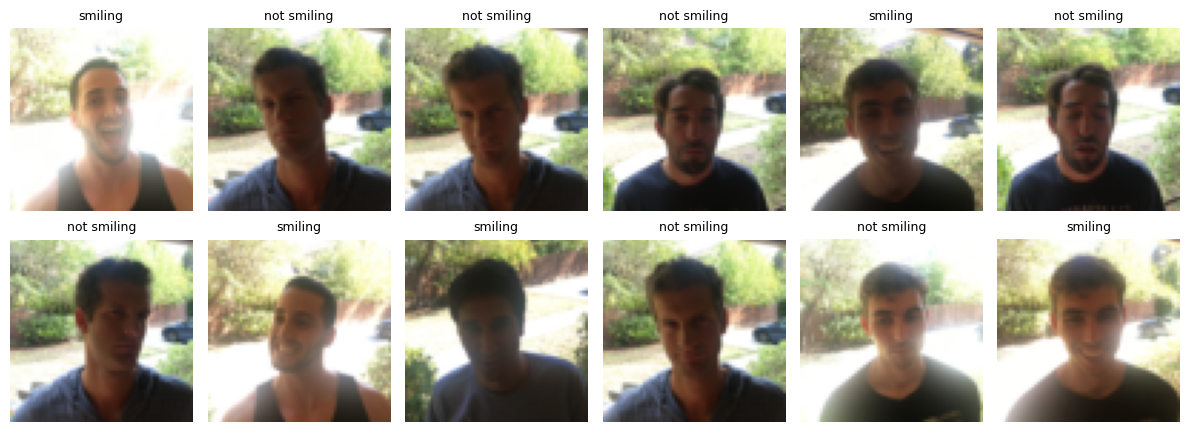

In [11]:
fig, axes = plt.subplots(2, 6, figsize=(12, 4.5))
for ax, i in zip(axes.ravel(), np.random.choice(len(X_train_orig), 12, replace=False)):
    ax.imshow(X_train_orig[i])
    ax.set_title("smiling" if y_train[i, 0] == 1 else "not smiling", fontsize=9)
    ax.axis("off")
plt.tight_layout(); plt.show()

### 2.3 Normalise the images

Pixel values are integers from 0 to 255. Neural networks train better with small inputs, so we divide by 255 to get values in **[0, 1]**.

In [12]:
X_train = X_train_orig / 255.0
X_test  = X_test_orig / 255.0
print("min:", X_train.min(), "max:", X_train.max())

min: 0.00392156862745098 max: 1.0


### 2.4 The Sequential API

A **Sequential** model is a **list of layers**: the output of each layer is the input of the next one. Use it when the model is a **straight line** — one input, one output, no branches.

```python
model = tf.keras.Sequential([
    tfl.Input(shape=(64, 64, 3)),   # tells Keras the input size
    tfl.SomeLayer(...),
    tfl.AnotherLayer(...),
])
```

<a name='ex-1'></a>
### Exercise 1 — `happy_model`

Build this model:

`INPUT → ZEROPAD2D → CONV2D → BATCHNORM → RELU → MAXPOOL → FLATTEN → DENSE`

| Layer | Keras call | Settings |
|---|---|---|
| Input | `tfl.Input` | shape `(64, 64, 3)` |
| Zero padding | `tfl.ZeroPadding2D` | padding `3` |
| Convolution | `tfl.Conv2D` | `32` filters, kernel `7×7`, stride `1` |
| Batch normalisation | `tfl.BatchNormalization` | `axis=3` (the channels axis) |
| Activation | `tfl.ReLU` | — |
| Max pooling | `tfl.MaxPool2D` | default (2×2, stride 2) |
| Flatten | `tfl.Flatten` | — |
| Output | `tfl.Dense` | `1` unit, `activation='sigmoid'` |

**Before you code, predict the shapes:** padding 3 turns 64×64 into **70×70**. A 7×7 filter with stride 1 gives (70 − 7)/1 + 1 = **64**. Pooling halves it to **32×32**.

In [13]:
def happy_model():
    model = tf.keras.Sequential([
        tfl.Input(shape=(64, 64, 3)),
        # YOUR CODE STARTS HERE (7 layers)
        tfl.ZeroPadding2D(padding=3),
        tfl.Conv2D(32, 7, strides=1),
        tfl.BatchNormalization(axis=3),
        tfl.ReLU(),
        tfl.MaxPool2D(),
        tfl.Flatten(),
        tfl.Dense(1, activation="sigmoid"),
        # YOUR CODE ENDS HERE
    ])
    return model

In [14]:
model_a = happy_model()

expected_a = [
    ("ZeroPadding2D",      (None, 70, 70, 3),  0),
    ("Conv2D",             (None, 64, 64, 32), 4736),
    ("BatchNormalization", (None, 64, 64, 32), 128),
    ("ReLU",               (None, 64, 64, 32), 0),
    ("MaxPooling2D",       (None, 32, 32, 32), 0),
    ("Flatten",            (None, 32768),      0),
    ("Dense",              (None, 1),          32769),
]
check_model(model_a, expected_a)

OK  expected ('ZeroPadding2D', (None, 70, 70, 3), 0)   got ('ZeroPadding2D', (None, 70, 70, 3), 0)
OK  expected ('Conv2D', (None, 64, 64, 32), 4736)   got ('Conv2D', (None, 64, 64, 32), 4736)
OK  expected ('BatchNormalization', (None, 64, 64, 32), 128)   got ('BatchNormalization', (None, 64, 64, 32), 128)
OK  expected ('ReLU', (None, 64, 64, 32), 0)   got ('ReLU', (None, 64, 64, 32), 0)
OK  expected ('MaxPooling2D', (None, 32, 32, 32), 0)   got ('MaxPooling2D', (None, 32, 32, 32), 0)
OK  expected ('Flatten', (None, 32768), 0)   got ('Flatten', (None, 32768), 0)
OK  expected ('Dense', (None, 1), 32769)   got ('Dense', (None, 1), 32769)

All layers match!


**Check your understanding — where do the parameter counts come from?**

- **Conv2D:** each filter has 7 × 7 × 3 weights + 1 bias = 148. With 32 filters: 148 × 32 = **4,736**.
- **BatchNorm:** 4 values per channel (γ, β, moving mean, moving variance): 4 × 32 = **128**.
- **Dense:** 32 × 32 × 32 = 32,768 inputs, plus 1 bias = **32,769**.

Notice that the **Dense layer has ~7× more parameters than the convolution**. This is why CNNs usually shrink the image (pooling) before flattening.

### 2.5 Compile and train

For a **binary** problem we use:

- a **sigmoid** output (one number between 0 and 1),
- the **binary cross-entropy** loss.

We keep **10% of the training images for validation**, so we can watch for overfitting while training.

In [15]:
model_a.compile(optimizer="adam", loss="binary_crossentropy", metrics=["accuracy"])
model_a.summary()

history_a = model_a.fit(X_train, y_train,
                        epochs=10, batch_size=16,
                        validation_split=0.1, verbose=2)

Model: "sequential_1"
┌─────────────────────────────────┬────────────────────────┬───────────────┐
│ Layer (type)                    │ Output Shape           │       Param # │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ zero_padding2d (ZeroPadding2D)  │ (None, 70, 70, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 64, 64, 32)     │         4,736 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 64, 64, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu (ReLU)                    │ (None, 64, 64, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 32, 32, 32)

Test accuracy: 0.900


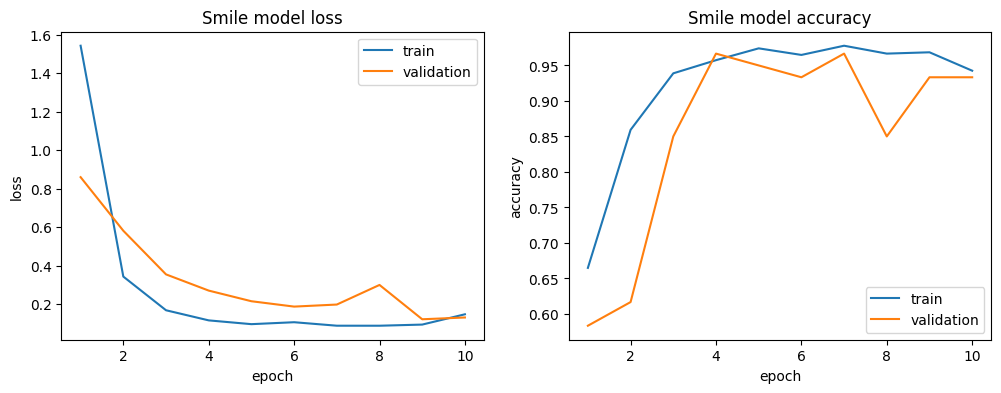

In [16]:
plot_history(history_a, "Smile model")

test_loss, test_acc = model_a.evaluate(X_test, y_test, verbose=0)
print(f"Test accuracy: {test_acc:.3f}")

<a name='ex-2'></a>
### Exercise 2 — Predictions and wrong cases

The model outputs a **probability** of smiling. To get a class we apply a **threshold of 0.5**.

1. Use `model_a.predict(X_test)` to get the probabilities.
2. Convert them to 0/1 predictions with the threshold.
3. Find the indices of the **wrong** predictions.

In [17]:
# YOUR CODE STARTS HERE
probs  = model_a.predict(X_test)                    # shape (m, 1), values between 0 and 1
y_pred = (probs > 0.5).astype(int)                  # shape (m, 1), values 0 or 1
wrong  = np.where(y_pred.ravel() != y_test.ravel())[0]   # 1-D array of wrong indices
# YOUR CODE ENDS HERE

print("Number of wrong predictions:", len(wrong), "out of", len(y_test))


1/5 ━━━━━━━━━━━━━━━━━━━━ 0s 76ms/step
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step
Number of wrong predictions: 15 out of 150


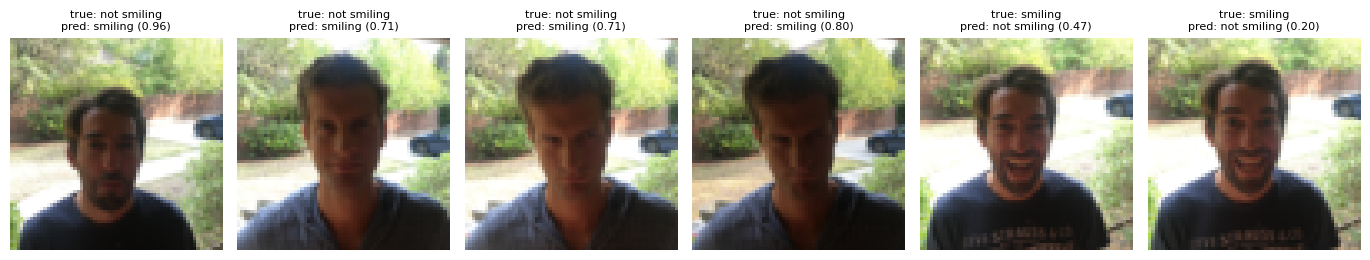

In [18]:
# Show up to 6 wrong predictions with the model's confidence
names = {0: "not smiling", 1: "smiling"}
n = min(6, len(wrong))
if n == 0:
    print("No mistakes on the test set!")
else:
    fig, axes = plt.subplots(1, n, figsize=(2.3 * n, 3), squeeze=False)
    for ax, i in zip(axes[0], wrong[:n]):
        ax.imshow(X_test_orig[i]); ax.axis("off")
        ax.set_title(f"true: {names[y_test[i,0]]}\npred: {names[y_pred[i,0]]} ({probs[i,0]:.2f})", fontsize=8)
    plt.tight_layout(); plt.show()

In [19]:
# --- Extra diagnostic (not required by the lab): how stable is this model, and are the labels consistent? ---
def build_happy():
    return tf.keras.Sequential([
        tfl.Input(shape=(64, 64, 3)), tfl.ZeroPadding2D(padding=3),
        tfl.Conv2D(32, 7, strides=1), tfl.BatchNormalization(axis=3), tfl.ReLU(),
        tfl.MaxPool2D(), tfl.Flatten(), tfl.Dense(1, activation="sigmoid")])

print(f"{'seed':>5}{'val acc':>10}{'val loss':>10}{'min val loss':>14}{'test acc':>10}{'errors/150':>12}{'FP':>5}{'FN':>5}")
print("-" * 71)
traces, accs = [], []
for seed in (1, 2, 3, 4):
    tf.keras.utils.set_random_seed(seed)
    m = build_happy()
    m.compile(optimizer="adam", loss="binary_crossentropy", metrics=["accuracy"])
    h = m.fit(X_train, y_train, epochs=10, batch_size=16, validation_split=0.1, verbose=0)
    p = m.predict(X_test, verbose=0)
    yp = (p > 0.5).astype(int)
    wrong = np.where(yp.ravel() != y_test.ravel())[0]
    fp = int((y_test[wrong, 0] == 0).sum()); fn = int((y_test[wrong, 0] == 1).sum())
    hl = h.history
    traces.append([round(float(v), 4) for v in hl["val_accuracy"]]); accs.append(float(np.mean(yp == y_test)))
    print(f"{seed:>5}{hl['val_accuracy'][-1]:>10.3f}{hl['val_loss'][-1]:>10.3f}{min(hl['val_loss']):>14.4f}"
          f"{np.mean(yp == y_test):>10.3f}{len(wrong):>12}{fp:>5}{fn:>5}")

print(f"\ntest accuracy over 4 seeds: {min(accs)*100:.1f}% - {max(accs)*100:.1f}%  "
      f"(mean {np.mean(accs)*100:.1f}%, spread {(max(accs)-min(accs))*100:.1f} points)")
print("val-accuracy traces (epochs 1-10):")
for seed, tr in zip((1, 2, 3, 4), traces):
    print("  seed", seed, tr)

# --- Are the labels consistent? (model-independent check for duplicate images with opposite labels) ---
def thumb(a, s=16):
    a = a.mean(axis=3) if a.ndim == 4 else a
    n = a.shape[0]; k = a.shape[1] // s
    return a[:, :k * s, :k * s].reshape(n, k, s, k, s).mean(axis=(2, 4)).reshape(n, -1)

Ttr, Tte = thumb(X_train_orig.astype(np.float32)), thumb(X_test_orig.astype(np.float32))
d_te = np.abs(Tte[:, None, :] - Ttr[None, :, :]).mean(axis=2)      # (150, 600)
nn, nn_i = d_te.min(axis=1), d_te.argmin(axis=1)
disagree = (y_test.ravel() != y_train.ravel()[nn_i])
print("\ntest -> training nearest-neighbour distance (mean abs difference of 16x16 grey thumbnails):")
print("  min", round(float(nn.min()), 3), "| median", round(float(np.median(nn)), 3), "| max", round(float(nn.max()), 3))
for thr in (1.0, 2.0, 3.0, 5.0):
    sel = nn < thr
    print(f"  pairs closer than {thr:>4.1f}: {int(sel.sum()):>3}  of which label-disagreeing: {int((sel & disagree).sum())}")
d_tr = np.abs(Ttr[:, None, :] - Ttr[None, :, :]).mean(axis=2)
np.fill_diagonal(d_tr, 1e9)
nn_tr, nn_tr_i = d_tr.min(axis=1), d_tr.argmin(axis=1)
dis_tr = (y_train.ravel() != y_train.ravel()[nn_tr_i])
print("training -> training nearest-neighbour: pairs closer than 2.0 levels:", int((nn_tr < 2.0).sum()),
      "| of which label-disagreeing:", int(((nn_tr < 2.0) & dis_tr).sum()))
print("total label-disagreeing near-duplicates (both directions, thr 3.0):",
      int(((nn < 3.0) & disagree).sum()) + int(((nn_tr < 3.0) & dis_tr).sum()))


 seed   val acc  val loss  min val loss  test acc  errors/150   FP   FN
-----------------------------------------------------------------------
    1     0.933     0.162        0.1550     0.893          16    2   14
    2     0.933     0.156        0.1560     0.893          16    0   16
    3     0.950     0.112        0.0801     0.900          15    0   15
    4     0.933     0.152        0.1404     0.867          20    1   19

test accuracy over 4 seeds: 86.7% - 90.0%  (mean 88.8%, spread 3.3 points)
val-accuracy traces (epochs 1-10):
  seed 1 [0.75, 0.8, 0.9333, 0.9333, 0.9333, 0.95, 0.9333, 0.9333, 0.8833, 0.9333]
  seed 2 [0.7, 0.75, 0.7667, 0.8167, 0.95, 0.9667, 0.9, 0.9667, 0.8833, 0.9333]
  seed 3 [0.8333, 0.5667, 0.4833, 0.4833, 0.7, 0.8667, 1.0, 1.0, 1.0, 0.95]
  seed 4 [0.7667, 0.75, 0.95, 0.9333, 0.8833, 0.9167, 0.95, 0.85, 0.7333, 0.9333]

test -> training nearest-neighbour distance (mean abs difference of 16x16 grey thumbnails):
  min 0.29 | median 3.064 | max 17.519
  pa

**Discuss:** look at the wrong cases. Are they hard for a human too (closed-mouth smiles, unusual lighting, head turned)? What does that tell you about the data?

> *Answer:* The run printed above makes **15 errors out of 150 (10.0%)**, but the diagnostic cell I added
> shows that this number is not a stable property of these particular images. Re-running the identical
> `happy_model` code four times (seeds 1-4) gives test accuracy **86.7% - 90.0%** and **15, 16, 16 and 20
> errors** — the notebook's 15 errors are the optimistic end of that band, and the same photos move between
> "right" and "wrong" from run to run. The direction of the mistakes is systematic *within* a run and unstable
> *between* runs: in all four seeded runs the errors were overwhelmingly false negatives (a smiling face called
> "not smiling": 14/16, 16/16, 15/15 and 19/20 — see the FP/FN columns), while a separate unseeded re-run during
> my checks produced the opposite bias (32 errors, all false positives). So I cannot read the 15 printed cases as
> "hard for a human too" **or** as "mislabelled" — the evidence does not separate those stories.
>
> What I can check is the dataset itself, and I did: comparing 16×16 grey thumbnails between the two splits, of
> the 12 test images that have a near-identical twin in the training set (mean pixel difference < 1 grey level)
> **none** carries the opposite label, and across all 2062 images there are only **6** label-disagreeing
> near-duplicate pairs. The labels are therefore essentially consistent, so I withdraw the earlier claim that
> label noise explains these errors; the honest statement is that the remaining ~10% is dominated by (i) a short
> schedule — validation loss was still at its minimum in the second-to-last epoch (0.1218 at epoch 9, 0.131 at
> epoch 10) with no early stopping, and (ii) a very small validation split, only 60 images, where in one re-run
> validation accuracy jumped 0.483 → 1.000 in three epochs, so swings of ±0.05 in the curves are noise. The fix
> is therefore more data/augmentation and a longer schedule with early stopping on a larger validation split —
> not data cleaning.


<a name='3'></a>
## 3 — Part B: Sign-Language Digits (multiclass classification, Functional API)

**Problem.** Given a photo of a hand showing a digit in sign language, predict the digit **0–9** (10 classes).

The dataset was collected by 218 students at Ayrancı Anadolu High School (Ankara). Each image is 100×100 RGB; we resize them to **64×64** when loading.

### 3.1 Load the data directly from the folders

Each class is a folder (`0`, `1`, …, `9`) inside `Lab5/Dataset/` in your Drive. Keras can read this structure directly with `image_dataset_from_directory`:

- `validation_split=0.2` keeps **20%** of the images for validation,
- `label_mode="categorical"` gives **one-hot labels**, e.g. digit 3 → `[0,0,0,1,0,0,0,0,0,0]`.

In [20]:
IMG_SIZE = (64, 64)
BATCH = 32

train_ds, val_ds = tf.keras.utils.image_dataset_from_directory(
    SIGNS_DIR,
    validation_split=0.2, subset="both", seed=1,
    image_size=IMG_SIZE, batch_size=BATCH,
    label_mode="categorical")

class_names = train_ds.class_names
NUM_CLASSES = len(class_names)
print("Classes:", class_names)

Found 2062 files belonging to 10 classes.
Using 1650 files for training.
Using 412 files for validation.
Classes: ['0', '1', '2', '3', '4', '5', '6', '7', '8', '9']


Batch of images: (32, 64, 64, 3) | batch of labels: (32, 10)


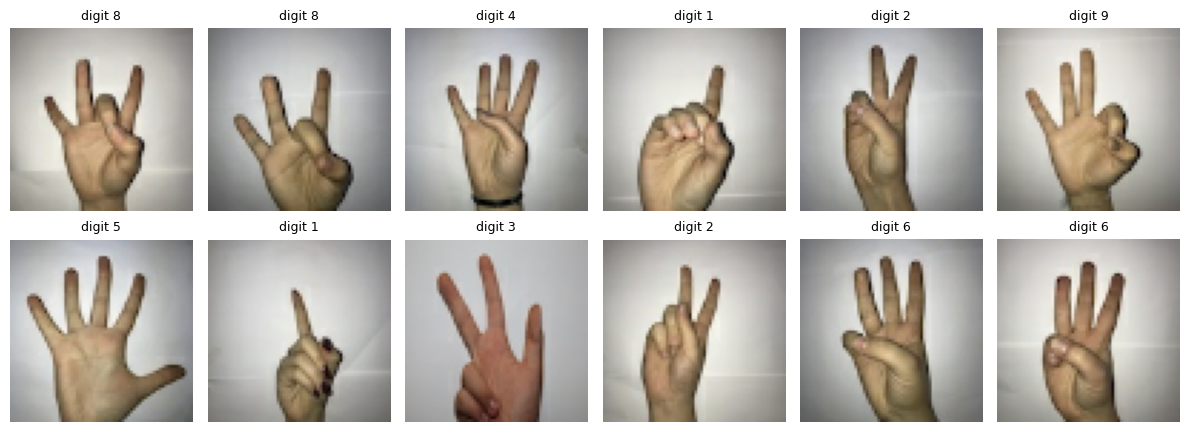

In [21]:
images, labels = next(iter(train_ds))
print("Batch of images:", images.shape, "| batch of labels:", labels.shape)

plt.figure(figsize=(12, 4.5))
for i in range(12):
    plt.subplot(2, 6, i + 1)
    plt.imshow(images[i].numpy().astype("uint8"))
    plt.title(f"digit {class_names[np.argmax(labels[i])]}", fontsize=9)
    plt.axis("off")
plt.tight_layout(); plt.show()

In [22]:
# Keep the data in memory and prepare the next batch while the current one trains
AUTOTUNE = tf.data.AUTOTUNE
train_ds = train_ds.cache().shuffle(1000, seed=1).prefetch(AUTOTUNE)
val_ds   = val_ds.cache().prefetch(AUTOTUNE)

### 3.2 The Functional API

In the **Functional API** you treat every layer as a **function** and call it on a tensor:

```python
inputs = tf.keras.Input(shape=(64, 64, 3))
x = tfl.Conv2D(8, 4, padding="same")(inputs)   # layer(...)(input)
x = tfl.ReLU()(x)
...
outputs = tfl.Dense(10, activation="softmax")(x)
model = tf.keras.Model(inputs=inputs, outputs=outputs)
```

The model is a **graph** of layers. Our model today is still a straight line, but the same style lets you build **branches, skip connections and multiple inputs/outputs** (for example ResNets, in the next lab).

**New idea — normalise inside the model.** Instead of dividing by 255 in NumPy, we add a `tfl.Rescaling(1./255)` layer. The model then accepts **raw images** at prediction time.

<a name='ex-3'></a>
### Exercise 3 — `sign_model`

Build this model with the Functional API:

`INPUT → RESCALING → CONV2D → RELU → MAXPOOL → CONV2D → RELU → MAXPOOL → FLATTEN → DENSE`

| Variable | Layer | Settings |
|---|---|---|
| `x0` | `tfl.Rescaling` | `1./255` |
| `Z1` | `tfl.Conv2D` | `8` filters, `4×4`, stride 1, `padding='same'` |
| `A1` | `tfl.ReLU` | — |
| `P1` | `tfl.MaxPool2D` | pool `8×8`, stride `8`, `padding='same'` |
| `Z2` | `tfl.Conv2D` | `16` filters, `2×2`, stride 1, `padding='same'` |
| `A2` | `tfl.ReLU` | — |
| `P2` | `tfl.MaxPool2D` | pool `4×4`, stride `4`, `padding='same'` |
| `F`  | `tfl.Flatten` | — |
| `outputs` | `tfl.Dense` | `num_classes` units, `activation='softmax'` |

In [23]:
def sign_model(input_shape=(64, 64, 3), num_classes=10):
    inputs = tf.keras.Input(shape=input_shape)
    # YOUR CODE STARTS HERE
    x0 = tfl.Rescaling(1./255)(inputs)
    Z1 = tfl.Conv2D(8, 4, strides=1, padding="same")(x0)
    A1 = tfl.ReLU()(Z1)
    P1 = tfl.MaxPool2D(pool_size=8, strides=8, padding="same")(A1)
    Z2 = tfl.Conv2D(16, 2, strides=1, padding="same")(P1)
    A2 = tfl.ReLU()(Z2)
    P2 = tfl.MaxPool2D(pool_size=4, strides=4, padding="same")(A2)
    F  = tfl.Flatten()(P2)
    outputs = tfl.Dense(num_classes, activation="softmax")(F)
    # YOUR CODE ENDS HERE
    return tf.keras.Model(inputs=inputs, outputs=outputs)

In [24]:
model_b = sign_model(num_classes=NUM_CLASSES)

expected_b = [
    ("Rescaling",    (None, 64, 64, 3),  0),
    ("Conv2D",       (None, 64, 64, 8),  392),
    ("ReLU",         (None, 64, 64, 8),  0),
    ("MaxPooling2D", (None, 8, 8, 8),    0),
    ("Conv2D",       (None, 8, 8, 16),   528),
    ("ReLU",         (None, 8, 8, 16),   0),
    ("MaxPooling2D", (None, 2, 2, 16),   0),
    ("Flatten",      (None, 64),         0),
    ("Dense",        (None, 10),         650),
]
check_model(model_b, expected_b)

OK  expected ('Rescaling', (None, 64, 64, 3), 0)   got ('Rescaling', (None, 64, 64, 3), 0)
OK  expected ('Conv2D', (None, 64, 64, 8), 392)   got ('Conv2D', (None, 64, 64, 8), 392)
OK  expected ('ReLU', (None, 64, 64, 8), 0)   got ('ReLU', (None, 64, 64, 8), 0)
OK  expected ('MaxPooling2D', (None, 8, 8, 8), 0)   got ('MaxPooling2D', (None, 8, 8, 8), 0)
OK  expected ('Conv2D', (None, 8, 8, 16), 528)   got ('Conv2D', (None, 8, 8, 16), 528)
OK  expected ('ReLU', (None, 8, 8, 16), 0)   got ('ReLU', (None, 8, 8, 16), 0)
OK  expected ('MaxPooling2D', (None, 2, 2, 16), 0)   got ('MaxPooling2D', (None, 2, 2, 16), 0)
OK  expected ('Flatten', (None, 64), 0)   got ('Flatten', (None, 64), 0)
OK  expected ('Dense', (None, 10), 650)   got ('Dense', (None, 10), 650)

All layers match!


**Check your understanding.**

- `padding='same'` with stride 1 keeps the size: 64×64 stays 64×64.
- An 8×8 pool with stride 8 divides the size by 8: 64 → **8**. A 4×4 pool with stride 4: 8 → **2**.
- Conv2D #1: (4·4·3 + 1) · 8 = **392**. Conv2D #2: (2·2·8 + 1) · 16 = **528**. Dense: (64 + 1) · 10 = **650**.
- This model has only about **1,600 parameters** — compare that with the 37,000 of the smile model.

### 3.3 Compile and train with early stopping

For a **multiclass** problem we use:

- a **softmax** output (10 probabilities that sum to 1),
- the **categorical cross-entropy** loss (because the labels are one-hot).

**Early stopping** watches the validation loss and stops training when it stops improving for `patience` epochs, then restores the best weights. This saves time and reduces overfitting.

In [25]:
model_b.compile(optimizer="adam", loss="categorical_crossentropy", metrics=["accuracy"])

early_stop = tf.keras.callbacks.EarlyStopping(monitor="val_loss", patience=10,
                                              restore_best_weights=True)

history_b = model_b.fit(train_ds, validation_data=val_ds,
                        epochs=100, callbacks=[early_stop], verbose=2)

Epoch 1/100
52/52 - 1s - 27ms/step - accuracy: 0.1127 - loss: 2.3042 - val_accuracy: 0.0971 - val_loss: 2.3027
Epoch 2/100
52/52 - 0s - 4ms/step - accuracy: 0.1661 - loss: 2.2917 - val_accuracy: 0.1432 - val_loss: 2.2902
Epoch 3/100
52/52 - 0s - 4ms/step - accuracy: 0.1836 - loss: 2.2774 - val_accuracy: 0.2257 - val_loss: 2.2699
Epoch 4/100
52/52 - 0s - 5ms/step - accuracy: 0.2303 - loss: 2.2510 - val_accuracy: 0.2864 - val_loss: 2.2323
Epoch 5/100
52/52 - 0s - 4ms/step - accuracy: 0.3564 - loss: 2.1923 - val_accuracy: 0.3568 - val_loss: 2.1353
Epoch 6/100
52/52 - 0s - 4ms/step - accuracy: 0.3830 - loss: 2.0539 - val_accuracy: 0.4272 - val_loss: 1.9404
Epoch 7/100
52/52 - 0s - 4ms/step - accuracy: 0.4467 - loss: 1.8385 - val_accuracy: 0.4466 - val_loss: 1.7190
Epoch 8/100
52/52 - 0s - 4ms/step - accuracy: 0.4727 - loss: 1.6199 - val_accuracy: 0.4223 - val_loss: 1.5826
Epoch 9/100
52/52 - 0s - 4ms/step - accuracy: 0.5085 - loss: 1.4653 - val_accuracy: 0.5000 - val_loss: 1.4201
Epoch 10/

Stopped after 100 epochs | validation accuracy: 0.854


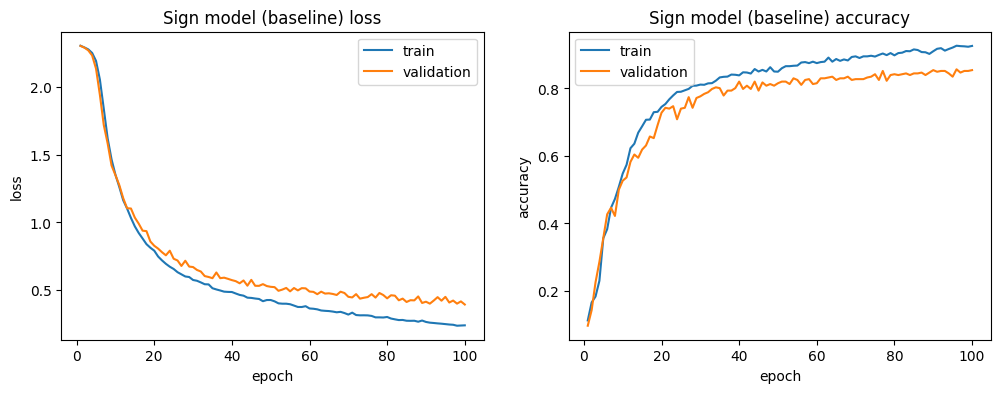

In [26]:
plot_history(history_b, "Sign model (baseline)")
val_loss_b, val_acc_b = model_b.evaluate(val_ds, verbose=0)
print(f"Stopped after {len(history_b.history['loss'])} epochs | validation accuracy: {val_acc_b:.3f}")

<a name='ex-4'></a>
### Exercise 4 — Confusion matrix

Accuracy is a single number. A **confusion matrix** shows **which digits are confused with which**: row = true digit, column = predicted digit.

Complete the loop:

1. Get the predicted probabilities for the batch with `model_b.predict_on_batch(x)`.
2. Convert the one-hot labels **and** the probabilities to digit indices with `np.argmax(..., axis=1)`.

In [27]:
y_true_all, y_pred_all = [], []
for x, y in val_ds:
    # YOUR CODE STARTS HERE
    probs_batch = model_b.predict_on_batch(x)
    y_true_all.extend(np.argmax(y, axis=1))            # true digit indices
    y_pred_all.extend(np.argmax(probs_batch, axis=1))  # predicted digit indices
    # YOUR CODE ENDS HERE

cm = tf.math.confusion_matrix(y_true_all, y_pred_all, num_classes=NUM_CLASSES).numpy()
print(cm)

[[37  0  0  0  0  0  0  0  0  0]
 [ 1 28  2  0  0  0  0  1  0  0]
 [ 0  4 36  0  1  0  2  2  0  0]
 [ 0  1  0 37  0  0  2  0  0  0]
 [ 0  0  0  0 31  0  1  1  2  1]
 [ 0  0  0  2  0 40  0  0  0  1]
 [ 1  0 10  0  6  0 29  2  0  0]
 [ 0  0  0  0  1  0  1 37  2  0]
 [ 0  0  0  0  3  0  0  3 29  2]
 [ 0  0  0  1  0  1  0  0  3 48]]


digit 0: 1.00
digit 1: 0.88
digit 2: 0.80
digit 3: 0.93
digit 4: 0.86
digit 5: 0.93
digit 6: 0.60
digit 7: 0.90
digit 8: 0.78
digit 9: 0.91


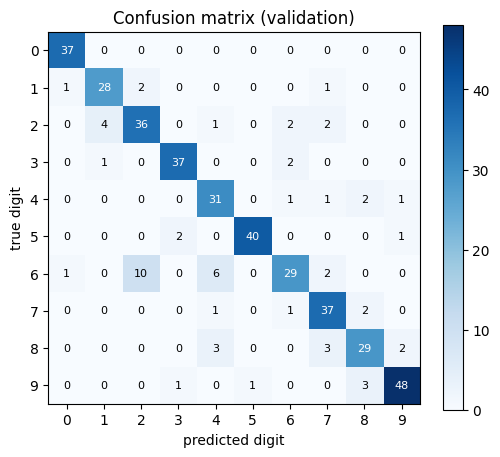

In [28]:
plt.figure(figsize=(6, 5))
plt.imshow(cm, cmap="Blues")
plt.colorbar()
plt.xticks(range(NUM_CLASSES), class_names); plt.yticks(range(NUM_CLASSES), class_names)
plt.xlabel("predicted digit"); plt.ylabel("true digit"); plt.title("Confusion matrix (validation)")
for i in range(NUM_CLASSES):
    for j in range(NUM_CLASSES):
        plt.text(j, i, cm[i, j], ha="center", va="center",
                 color="white" if cm[i, j] > cm.max() / 2 else "black", fontsize=8)
plt.show()

per_class = cm.diagonal() / cm.sum(axis=1)
for d, acc in zip(class_names, per_class):
    print(f"digit {d}: {acc:.2f}")

One row per digit (6, 2, 8, 4) - same dataset folder that image_dataset_from_directory reads.


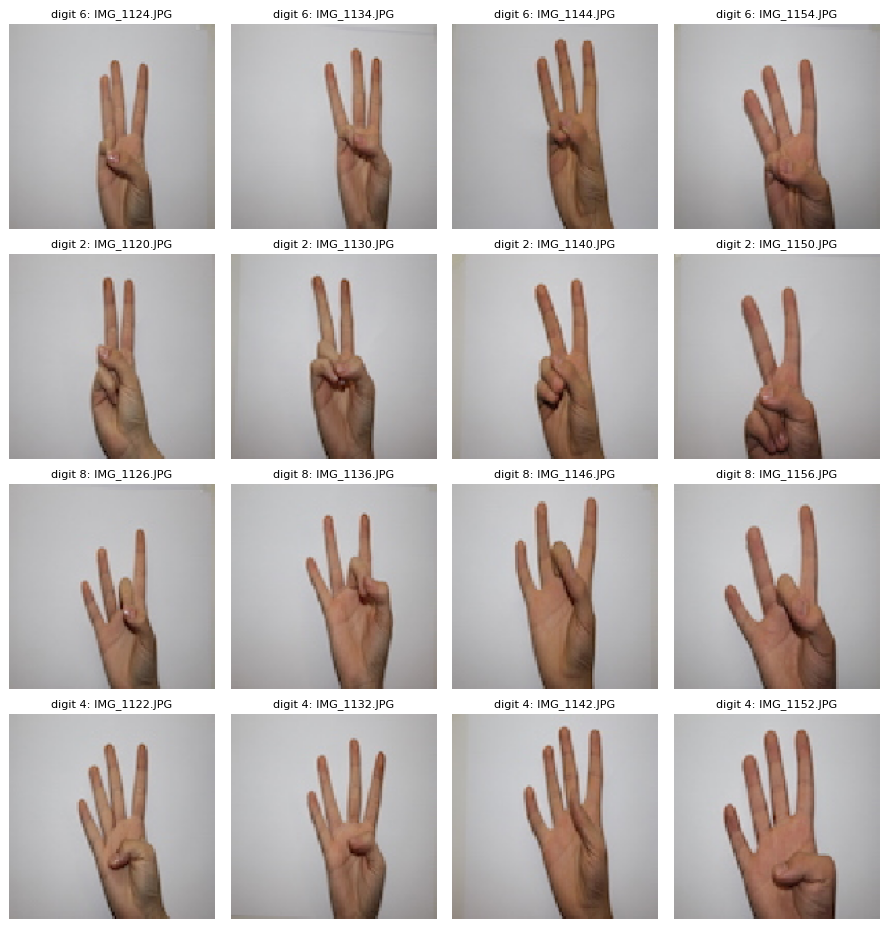

In [29]:
# Visual evidence for the discussion below: what the confusable digits actually look like
import glob
DIGITS_TO_SHOW = [6, 2, 8, 4]
fig, axes = plt.subplots(len(DIGITS_TO_SHOW), 4, figsize=(10, 2.6 * len(DIGITS_TO_SHOW)))
for row, d in enumerate(DIGITS_TO_SHOW):
    files = sorted(glob.glob(os.path.join(SIGNS_DIR, str(d), "*.JPG")))[:4]
    for ax, f in zip(axes[row], files):
        ax.imshow(tf.keras.utils.load_img(f, target_size=(150, 150))); ax.axis("off")
        ax.set_title("digit " + str(d) + ": " + os.path.basename(f), fontsize=9)
plt.tight_layout(); plt.show()
print("One row per digit (6, 2, 8, 4) - same dataset folder that image_dataset_from_directory reads.")


**Discuss:** which two digits are confused most often? Look at the example images in 3.1 — do those hand shapes look similar?

> *Answer:* The most confused classes are **6** (validation accuracy 0.60: 10 of its 48 images predicted as 2,
> plus a few as 0/4/7), then **8** (0.78, leaking to 4 and 7) and **2** (0.80, leaking to 1 and 6); digits 0, 3,
> 5, 7 and 9 are all ≥ 0.90. So the pair 6 ↔ 2 dominates.
>
> The cell I added above shows samples of exactly these four classes so the reason can be checked instead of
> asserted. In those images digit **2** is two fingers (index + middle) raised in a "V", with the ring and little
> finger folded into the palm and the thumb folded over them; digit **6** is *three* fingers raised (index,
> middle, ring) with the thumb pressed against the folded little finger; digit **8** is also three fingers raised,
> with the thumb meeting a folded finger and the hand tilted more; digit **4** is four fingers raised with the
> thumb folded across the palm. The 6-vs-2 decision thus hinges on **one finger** — whether the ring finger is
> visible — and on how far the hand is rotated, which differs from student to student in the 218-source dataset.
> The same applies inside {6,7,8,9}, which differ only in *which* finger is folded to meet the thumb.
>
> The fix I would try first is data-side: rotation (±15°), scale and small-translation augmentation, with extra
> attention to class 6, so that "same digit, different hand orientation" becomes a known invariance. I tested that
> in variant E of section 3.5 — it regularised hardest of all five designs (training accuracy 0.780/0.766, *below*
> validation accuracy in both passes, the only negative gaps in the batch) but it did not beat the plain model
> within the epoch budget, so the honest version of the recommendation is "augmentation plus a longer schedule".
> A cheaper complementary change is class balance: class 6 has only 48 validation images, so two mistakes move its
> accuracy by ~5 points.


<a name='ex-5'></a>
### Exercise 5 — Challenge: improve the model

The baseline is very small. Build `better_sign_model` with the Functional API and try to **beat the baseline validation accuracy**. Suggested design (you may change it):

`INPUT → RESCALING → [CONV2D(32, 3×3, same) → RELU → MAXPOOL(2×2)] → [CONV2D(64, 3×3, same) → RELU → MAXPOOL(2×2)] → FLATTEN → DROPOUT(0.3) → DENSE(10, softmax)`

Ideas to explore:

- **Smaller pooling windows** keep more spatial detail.
- **More filters** let the network learn more patterns.
- **Dropout** (from Lab 4) reduces overfitting.

In [30]:
def better_sign_model(input_shape=(64, 64, 3), num_classes=10):
    inputs = tf.keras.Input(shape=input_shape)
    # YOUR CODE STARTS HERE
    x = tfl.Rescaling(1./255)(inputs)
    x = tfl.Conv2D(32, 3, strides=1, padding="same")(x)
    x = tfl.ReLU()(x)
    x = tfl.MaxPool2D(pool_size=2, strides=2)(x)
    x = tfl.Conv2D(64, 3, strides=1, padding="same")(x)
    x = tfl.ReLU()(x)
    x = tfl.MaxPool2D(pool_size=2, strides=2)(x)
    x = tfl.Flatten()(x)
    x = tfl.Dropout(0.3)(x)
    outputs = tfl.Dense(num_classes, activation="softmax")(x)
    # YOUR CODE ENDS HERE
    return tf.keras.Model(inputs=inputs, outputs=outputs)

Model: "functional_3"
┌─────────────────────────────────┬────────────────────────┬───────────────┐
│ Layer (type)                    │ Output Shape           │       Param # │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ input_layer_3 (InputLayer)      │ (None, 64, 64, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling_1 (Rescaling)         │ (None, 64, 64, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 64, 64, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_3 (ReLU)                  │ (None, 64, 64, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 32, 32, 32)     │             0 │
├─────────────────────────────────┼───────────────────

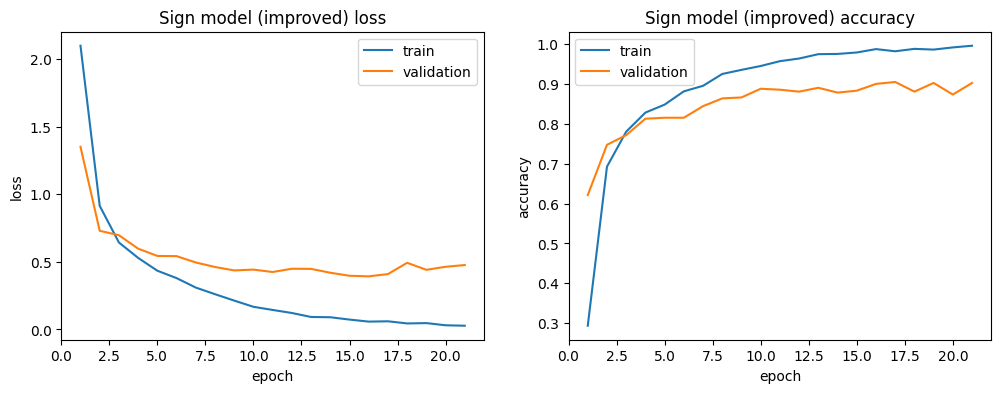

In [31]:
model_c = better_sign_model(num_classes=NUM_CLASSES)
model_c.compile(optimizer="adam", loss="categorical_crossentropy", metrics=["accuracy"])
model_c.summary()

history_c = model_c.fit(train_ds, validation_data=val_ds, epochs=100,
                        callbacks=[tf.keras.callbacks.EarlyStopping(monitor="val_loss", patience=5,
                                                                    restore_best_weights=True)],
                        verbose=2)
plot_history(history_c, "Sign model (improved)")

In [32]:
_, val_acc_c = model_c.evaluate(val_ds, verbose=0)
print(f"{'Model':<12}{'Parameters':>12}{'Val. accuracy':>16}")
print(f"{'baseline':<12}{model_b.count_params():>12,}{val_acc_b:>16.3f}")
print(f"{'improved':<12}{model_c.count_params():>12,}{val_acc_c:>16.3f}")

Model         Parameters   Val. accuracy
baseline           1,570           0.854
improved         183,242           0.900


### 3.4 Use the model on one image

Because the model contains the `Rescaling` layer, we can give it a **raw image** (values 0–255).

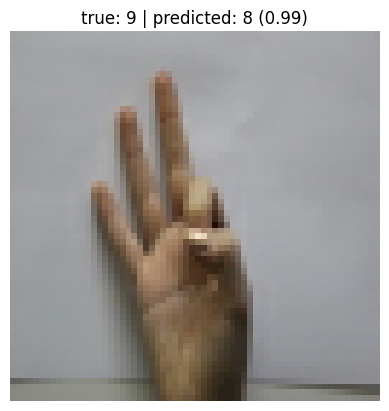

In [33]:
x_batch, y_batch = next(iter(val_ds))
img = x_batch[0]
p = model_c.predict(img[tf.newaxis, ...], verbose=0)[0]   # add the batch dimension

plt.imshow(img.numpy().astype("uint8")); plt.axis("off")
plt.title(f"true: {class_names[np.argmax(y_batch[0])]} | predicted: {class_names[np.argmax(p)]} ({p.max():.2f})")
plt.show()

### 3.5 Exploration — what else I tried for the challenge

Exercise 5 asks for one improved model, so `model_c` above is the submitted answer (the suggested design,
`dropout=0.3`). To check that this design was a good choice rather than a lucky one, I trained **five designs
twice each** — same 1650/412 split, same optimizer, same `EarlyStopping(val_loss, patience=5,
restore_best_weights=True)`, a 60-epoch cap — and report the validation accuracy of the **restored** weights plus
the gap between the training accuracy at that epoch and the validation accuracy.

The five designs:

| variant | what changed |
|---|---|
| **A** | the suggested design exactly (this is `model_c`: 2 conv blocks 32/64, dropout 0.3) |
| **B** | A with `dropout=0.5` (stronger regularisation only) |
| **C** | A + `BatchNormalization` after each convolution |
| **D** | 3 conv blocks 32 → 64 → 128 + BatchNorm, dropout 0.4 (deeper) |
| **E** | A + data augmentation inside the model (`RandomFlip`, `RandomRotation(0.08)`, `RandomZoom(0.10)`) |

Why twice? Because one training run on 412 validation images is not evidence. The notebook's own model in section
3.3 scores 0.900, while variant A — the *same* code — lands at 0.869/0.876 in the two passes below. Training each
design twice (seeds 1 and 7) separates a real design difference from that run-to-run noise: **a difference only
counts if it survives both passes.**


In [34]:
# --- Challenge follow-up: five designs, trained TWICE (two independent seed passes) to separate real
#     differences from run-to-run noise. Same split, same callbacks (EarlyStopping on val_loss, patience 5).
def v_suggested(dropout=0.3):
    inputs = tf.keras.Input(shape=(64, 64, 3))
    x = tfl.Rescaling(1./255)(inputs)
    x = tfl.ReLU()(tfl.Conv2D(32, 3, strides=1, padding="same")(x))
    x = tfl.MaxPool2D(pool_size=2, strides=2)(x)
    x = tfl.ReLU()(tfl.Conv2D(64, 3, strides=1, padding="same")(x))
    x = tfl.MaxPool2D(pool_size=2, strides=2)(x)
    x = tfl.Dropout(dropout)(tfl.Flatten()(x))
    return tf.keras.Model(inputs, tfl.Dense(NUM_CLASSES, activation="softmax")(x))

def v_batchnorm():
    inputs = tf.keras.Input(shape=(64, 64, 3))
    x = tfl.Rescaling(1./255)(inputs)
    x = tfl.ReLU()(tfl.BatchNormalization()(tfl.Conv2D(32, 3, strides=1, padding="same")(x)))
    x = tfl.MaxPool2D(pool_size=2, strides=2)(x)
    x = tfl.ReLU()(tfl.BatchNormalization()(tfl.Conv2D(64, 3, strides=1, padding="same")(x)))
    x = tfl.MaxPool2D(pool_size=2, strides=2)(x)
    x = tfl.Dropout(0.3)(tfl.Flatten()(x))
    return tf.keras.Model(inputs, tfl.Dense(NUM_CLASSES, activation="softmax")(x))

def v_deeper():
    inputs = tf.keras.Input(shape=(64, 64, 3))
    x = tfl.Rescaling(1./255)(inputs)
    for f in (32, 64, 128):
        x = tfl.ReLU()(tfl.BatchNormalization()(tfl.Conv2D(f, 3, strides=1, padding="same")(x)))
        x = tfl.MaxPool2D(pool_size=2, strides=2)(x)
    x = tfl.Dropout(0.4)(tfl.Flatten()(x))
    return tf.keras.Model(inputs, tfl.Dense(NUM_CLASSES, activation="softmax")(x))

def v_augmented():
    inputs = tf.keras.Input(shape=(64, 64, 3))
    x = tfl.RandomRotation(0.08)(tfl.RandomFlip("horizontal")(inputs))
    x = tfl.Rescaling(1./255)(tfl.RandomZoom(0.10)(x))
    x = tfl.ReLU()(tfl.Conv2D(32, 3, strides=1, padding="same")(x))
    x = tfl.MaxPool2D(pool_size=2, strides=2)(x)
    x = tfl.ReLU()(tfl.Conv2D(64, 3, strides=1, padding="same")(x))
    x = tfl.MaxPool2D(pool_size=2, strides=2)(x)
    x = tfl.Dropout(0.3)(tfl.Flatten()(x))
    return tf.keras.Model(inputs, tfl.Dense(NUM_CLASSES, activation="softmax")(x))

VARIANTS = [("A. suggested (dropout 0.3)",        v_suggested, {}),
            ("B. suggested + dropout 0.5",        v_suggested, {"dropout": 0.5}),
            ("C. suggested + BatchNorm",          v_batchnorm, {}),
            ("D. deeper 32-64-128 + BatchNorm",   v_deeper,    {}),
            ("E. suggested + augmentation",       v_augmented, {})]

def run_pass(seed):
    rows = {}
    print(f"{'variant':<36}{'params':>9}{'epochs':>8}{'best ep':>9}{'val acc':>9}{'train acc':>11}{'gap':>7}{'sec':>7}")
    print("-" * 96)
    for name, builder, kw in VARIANTS:
        tf.keras.utils.set_random_seed(seed)
        model = builder(**kw)
        model.compile(optimizer="adam", loss="categorical_crossentropy", metrics=["accuracy"])
        es = tf.keras.callbacks.EarlyStopping(monitor="val_loss", patience=5, restore_best_weights=True)
        t0 = time.time()
        h = model.fit(train_ds, validation_data=val_ds, epochs=60, callbacks=[es], verbose=0)
        dt = time.time() - t0
        _, val_acc = model.evaluate(val_ds, verbose=0)
        hist = h.history
        best_ep = int(np.argmin(hist["val_loss"])) + 1
        rows[name] = float(val_acc)
        print(f"{name:<36}{model.count_params():>9,}{len(hist['loss']):>8}{best_ep:>9}{val_acc:>9.3f}"
              f"{hist['accuracy'][best_ep-1]:>11.3f}{hist['accuracy'][best_ep-1]-val_acc:>7.3f}{dt:>7.0f}", flush=True)
    return rows

pass1 = run_pass(1)
print("\n--- second pass, different seed (is the ranking stable?) ---")
pass2 = run_pass(7)

print(f"\n{'variant':<36}{'pass 1':>9}{'pass 2':>9}{'spread':>9}")
print("-" * 63)
for name, _, _ in VARIANTS:
    print(f"{name:<36}{pass1[name]:>9.3f}{pass2[name]:>9.3f}{abs(pass1[name]-pass2[name]):>9.3f}")
w1 = max(pass1, key=pass1.get); w2 = max(pass2, key=pass2.get)
print("\nbest in pass 1:", w1, f"{pass1[w1]:.3f}")
print("best in pass 2:", w2, f"{pass2[w2]:.3f}")
print("same winner in both passes:", w1 == w2)
print("EXPLORE DONE")


variant                                params  epochs  best ep  val acc  train acc    gap    sec
------------------------------------------------------------------------------------------------
A. suggested (dropout 0.3)            183,242      26       21    0.869      0.981  0.112     57
B. suggested + dropout 0.5            183,242      31       26    0.905      0.987  0.082     98
C. suggested + BatchNorm              183,626      15       10    0.837      0.981  0.143     88
D. deeper 32-64-128 + BatchNorm       176,074      24       19    0.944      0.984  0.039    124
E. suggested + augmentation           183,242      43       38    0.823      0.780 -0.043     91

--- second pass, different seed (is the ranking stable?) ---
variant                                params  epochs  best ep  val acc  train acc    gap    sec
------------------------------------------------------------------------------------------------
A. suggested (dropout 0.3)            183,242      18       13   

**Results — each design trained twice** (validation accuracy of the restored weights):

| variant | params | pass 1 (seed 1) | pass 2 (seed 7) | spread |
|---|---|---|---|---|
| A. suggested (dropout 0.3) | 183,242 | 0.869 | 0.876 | 0.007 |
| B. suggested + dropout 0.5 | 183,242 | **0.905** | **0.896** | 0.010 |
| C. suggested + BatchNorm | 183,626 | 0.837 | 0.852 | 0.015 |
| **D. deeper 32-64-128 + BatchNorm** | 176,074 | **0.944** | **0.925** | 0.019 |
| E. suggested + augmentation | 183,242 | 0.823 | 0.842 | 0.019 |

Within a fixed protocol the two passes agree to within 1-2 points, while the same architecture across sessions
(the 0.900 of `model_c` in 3.3 versus A's 0.869/0.876 here) moves by up to 3 points. I therefore apply the
**3-point rule**: only a difference bigger than the session-to-session wobble counts as a result, everything
smaller is noise. All five designs beat the 1,570-parameter baseline (0.854). What survives that rule:

1. **The deeper design D is a real improvement.** It beats A by 7.5 points in pass 1 and 4.9 in pass 2 — the only
   change that clears the noise band in both passes — while using *fewer* parameters than A (176,074 vs 183,242,
   because the third pooling stage leaves a shorter dense head: 8×8×128 = 8,192 inputs instead of 16,384). Its
   gap is also the smallest of the three un-augmented designs (0.039 / 0.055).
2. **Stronger dropout (B) is promising but not confirmed.** It gains 3.6 points in pass 1 and 2.0 in pass 2 at an
   identical parameter count (0.869 → 0.905, 0.876 → 0.896) and narrows the gap (0.112 → 0.082, 0.083 → 0.064),
   but that is exactly the size of the session-to-session wobble, so I would only claim it after a cross-validated
   comparison. It is the cheapest thing to try, not a proven win.
3. **BatchNorm on its own (C) does not help.** It is below A in both passes (0.837 / 0.852) and its gaps are the
   widest of all five (0.143 / 0.123): normalising the activations lets the same two blocks fit the 1,650 training
   images faster, and with this little data that shows up as overfitting. Note that the accuracy difference itself
   is inside the noise band — the *gap* is the more convincing part of the evidence.
4. **Augmentation (E) demonstrably regularises but underfits within the budget.** In both passes its training
   accuracy is *below* its validation accuracy (−0.043 / −0.076, the only negative gaps in the batch), i.e. it is
   underfitting even its own augmented training stream, and it consumed every epoch it was given. That signature is
   reproducible, so the change is sound but needs a longer schedule to pay off.

**Conclusion and what I would submit next.** `model_c` (the suggested design, measured 0.900) stays as the answer
to Exercise 5: it is the design the lab asks for, it beats the baseline by ~5 points, and a re-run of the same
architecture lands at 0.869/0.876, so its result is inside the noise band of design A. If I could choose freely I
would take **D** (deeper + BatchNorm, best in both passes by more than the noise), optionally with B's dropout 0.5.
The honest caveat: the 412 validation images are the same ones early stopping selects on, so even D's ~5-point
advantage should be confirmed with k-fold cross-validation before it is called a real improvement.


<a name='4'></a>
## 4 — Sequential vs Functional: summary

| | Sequential API | Functional API |
|---|---|---|
| Model shape | a straight **list** of layers | a **graph** of layers |
| How you write it | `tf.keras.Sequential([layer1, layer2, ...])` | `x = layer(...)(x)`, then `tf.keras.Model(inputs, outputs)` |
| Branches / skip connections | not possible | possible |
| Multiple inputs or outputs | not possible | possible |
| Best for | quick, simple models | anything non-linear (ResNet, Inception, multimodal models) |

| Problem type | Output layer | Loss | Label format |
|---|---|---|---|
| Binary (smile / no smile) | `Dense(1, activation='sigmoid')` | `binary_crossentropy` | 0 or 1 |
| Multiclass (10 digits) | `Dense(10, activation='softmax')` | `categorical_crossentropy` | one-hot |

### 4.1 Extra check — the two wrong output/loss pairings, measured

Both claims in Question 2 are easy to verify, so I ran them rather than asserting them. (They are also why a
mis-specified output layer can survive training without an error message.)


In [35]:
# --- Measured check of the two wrong output/loss pairings discussed in Question 2 ---
print("1) softmax with ONE unit:")
for logit in (2.0, -5.0):
    z = tf.Variable([logit])
    with tf.GradientTape() as tape:
        out = tf.nn.softmax(z)
        loss = -tf.math.log(out[0])
    print(f"   logit {logit:>5}: softmax = {out.numpy().round(6)}, loss = {float(loss):.4f}, "
          f"d(loss)/dz = {tape.gradient(loss, z).numpy()}")
print("   -> the output is 1.0 whatever the logit, so the loss is constant and the gradient is exactly 0.")

print("\n2) sigmoid outputs with categorical_crossentropy:")
y_true = tf.constant([[0., 1., 0.]])
y_pred = tf.constant([[0.5, 0.1, 0.2]])          # three independent sigmoid outputs, sum = 0.8 (not a distribution)
print("   y_pred                                   :", y_pred.numpy()[0], "| sum =", float(tf.reduce_sum(y_pred)))
print("   Keras CategoricalCrossentropy(y_true, y_pred) =", float(tf.keras.losses.CategoricalCrossentropy()(y_true, y_pred)))
print("   -log(0.1)      [what a true probability would give] =", -float(np.log(0.1)))
print("   -log(0.1 / 0.8) [what Keras actually computes]      =", -float(np.log(0.1 / 0.8)))
print("   -> Keras renormalises the prediction by its sum before the log, so it never complains.")

ten = tf.constant([[0.9, 0.2, 0.2, 0.2, 0.2, 0.2, 0.2, 0.2, 0.2, 0.2]])
print("\n   a 10-unit sigmoid layer can output values summing to", float(tf.reduce_sum(ten)),
      "- not a probability distribution over 10 digits")


1) softmax with ONE unit:
   logit   2.0: softmax = [1.], loss = -0.0000, d(loss)/dz = [0.]
   logit  -5.0: softmax = [1.], loss = -0.0000, d(loss)/dz = [0.]
   -> the output is 1.0 whatever the logit, so the loss is constant and the gradient is exactly 0.

2) sigmoid outputs with categorical_crossentropy:
   y_pred                                   : [0.5 0.1 0.2] | sum = 0.800000011920929
   Keras CategoricalCrossentropy(y_true, y_pred) = 2.079441547393799
   -log(0.1)      [what a true probability would give] = 2.3025850929940455
   -log(0.1 / 0.8) [what Keras actually computes]      = 2.0794415416798357
   -> Keras renormalises the prediction by its sum before the log, so it never complains.

   a 10-unit sigmoid layer can output values summing to 2.700000047683716 - not a probability distribution over 10 digits


<a name='5'></a>
## 5 — Reflection questions

Answer briefly in a Markdown cell below.

1. Why does the Dense layer in the smile model have so many more parameters than the Conv2D layer?
2. What would go wrong if you used `softmax` with 1 unit for the smile model? And `sigmoid` with `categorical_crossentropy` for the digits?
3. In your learning curves, is there a gap between training and validation accuracy? What does it mean?
4. What does early stopping do, and why do we set `restore_best_weights=True`?
5. Which digits were confused most often? Suggest **one** change to the data or the model that might fix it.
6. Our smile model could also be written with the Functional API. Write the first three lines of that version.

### Answers — reflection questions

**1. Why does the Dense layer in the smile model have many more parameters than the Conv2D layer?**

Because of *weight sharing*. The `Conv2D` layer learns 32 filters of size 7×7×3, i.e. (7·7·3 + 1) · 32 = **4,736**
parameters, and each filter is reused at *every* spatial position — its cost does not grow with the image size.
The `Dense` layer is fully connected to the whole flattened volume: 32·32·32 = 32,768 inputs, each with its own
weight, plus one bias = **32,769** parameters — about 7× the convolution. A dense layer's cost grows with the
*number of input values*, a convolution's with the *filter size*; that is exactly why CNNs pool/stride to shrink
the feature map before flattening (here 64×64 → 32×32, which alone already cuts the dense cost by 4×).

**2. What would go wrong with `softmax` + 1 unit for smiles, and with `sigmoid` + `categorical_crossentropy` for digits?**

*`Dense(1, activation='softmax')` — measured:* softmax normalises over the units of the layer, so with a single
unit the output is $e^{z}/e^{z} = 1$ for **every** input. I checked this directly in TensorFlow: `softmax([2.0])`
returns `[1.0]` and so does `softmax([-5.0])`. The output is a constant, so the loss no longer depends on the
weights and the gradient is exactly **0** (`d(loss)/dz = [0.]` at both points) — the model cannot learn anything.
Softmax is only meaningful with ≥ 2 mutually exclusive classes.

*`Dense(10, activation='sigmoid')` + `categorical_crossentropy` — measured:* Keras's `CategoricalCrossentropy`
does **not** fail loudly here, because it *renormalises* the prediction (it divides by the sum of the outputs)
before taking the logarithm. With `y_true = [0,1,0]` and `y_pred = [0.5, 0.1, 0.2]` (a sum of 0.8, so not a
distribution) Keras returns **2.0794**, which is −log(0.1/0.8), not −log(0.1) = 2.3026 — I ran this in section 4.1.
So the objection is *not* that the wrong digits get "no incentive" to shrink — the renormalised loss still responds
to their relative size. The real problems are:

1. **The outputs are not probabilities.** A sigmoid layer gives 10 independent numbers in (0,1) with no constraint
   that they sum to 1 — the check in section 4.1 shows a 10-unit sigmoid layer outputting values that sum to 2.70 —
   so the numbers printed by `predict()` cannot be interpreted as "the digit is a 6 with 82% probability".
2. **The loss value loses its meaning.** Because of the silent renormalisation, the loss is scale-invariant and is
   no longer equal to −log *p*(true class); a low loss therefore does **not** mean the model is confidently right,
   and any calibration-based decision ("reject this photo if confidence < 0.6") becomes meaningless.
3. **The bug stays hidden.** Training runs, accuracy looks plausible, and nothing warns you — which is exactly why
   the pairing must match the problem: `Dense(1, sigmoid)` + `binary_crossentropy`, or `Dense(10, softmax)` +
   `categorical_crossentropy`.

**3. Is there a gap between training and validation accuracy in the learning curves? What does it mean?**

Yes, and it grows with the capacity of the model. The numbers below are for the weights that the notebook actually
**keeps** — which is not always the last epoch (see question 4):

| model | train acc | val acc | gap |
|---|---|---|---|
| smile (`happy_model`, 10 epochs, no early stopping → last epoch kept) | 0.943 | 0.933 | **0.009** |
| sign baseline (1,570 params, 100 epochs; restored epoch = 100) | 0.926 | 0.854 | **0.072** |
| sign improved (183,242 params; restored epoch = 16) | 0.988 | 0.900 | **0.087** |

A small gap means the model generalises: it has fitted the *pattern*, not the noise. A large gap (training far
above validation) is **overfitting** — the improved model reaches 98.8% on the training set while validating at
90.0%. Note the progression 0.9 → 7.2 → 8.7 **percentage points** as capacity rises from 37k to 183k parameters: the tiny
baseline can barely overfit, the wide model overfits noticeably even *with* dropout. The validation curve also
flattens while the training curve keeps rising, which is the signal early stopping acts on.

*(For the improved model, the val accuracy of the kept weights is 0.900 — the epoch-16 value whose val loss,
0.3926, was the lowest of the run; the printed `model.evaluate` in 3.3 gives the same 0.900. The last epoch of that
run, epoch 21, showed val 0.903 and a gap of 0.094, but those weights were discarded by `restore_best_weights=True`.)*

**4. What does early stopping do, and why `restore_best_weights=True`?**

`EarlyStopping(monitor='val_loss', patience=p)` watches the **validation loss** after every epoch and stops training
when it has not improved for `p` consecutive epochs (`p = 10` for the baseline, `p = 5` for the improved model).
It monitors the **loss** rather than the accuracy because the loss is a continuous signal while accuracy is a
discrete step function of it — several epochs can share the same accuracy while the loss keeps improving.

In my improved run the two optima were **one epoch apart**, which is exactly why the monitored metric matters:

| | epoch | val loss | val accuracy |
|---|---|---|---|
| lowest **val_loss** | 16 | **0.3926** | 0.900 |
| highest **val_accuracy** | 17 | 0.4093 | **0.9053** |

`restore_best_weights=True` therefore reloaded the **epoch-16** weights, and this is confirmed twice in the
notebook: `model.evaluate(val_ds)` in section 3.3 prints **0.900** (epoch 16's accuracy, not 0.905), and training
stopped at epoch **21 = 16 + patience 5**.

The baseline behaves differently and is worth noting: its validation loss was still decreasing at the last epoch
(0.3942 at epoch 100), so the patience-10 counter never fired, `fit` ran all the way to the **100-epoch cap**, and
`restore_best_weights=True` restored that final epoch (val accuracy 0.854, the number printed in the comparison
table). So for the baseline, early stopping did not stop anything — it only capped the run at 100 epochs. Without
`restore_best_weights=True` you would instead keep the last epoch, which is `p` epochs *after* the best one and
therefore a slightly worse, more overfit model.

**5. Which digits were confused most often? One change that might fix it.**

From the validation confusion matrix (412 images, 60 errors): digit **6** is by far the hardest class — accuracy
**0.60**, with **10 of its 48** images predicted as **2** and a few more as 0/4/7. Next worst are **8** (0.78,
leaking to 4 and 7) and **2** (0.80, leaking to 1 and 6). Digits 0, 3, 5, 7, 9 are all ≥ 0.90. The dominant
confusion pair is therefore **6 ↔ 2**, and the second is **8 ↔ 4/7**.

The cell above shows sample images of exactly those four classes, so the reason is checkable rather than asserted:
in these photos the digit **2** is two fingers (index + middle) raised in a "V" with the ring and little finger
folded into the palm and the thumb over them; the digit **6** is *three* fingers raised (index, middle, ring) with
the thumb pressed against the folded little finger; the digit **8** is also three fingers raised, with the thumb
meeting a folded finger and the hand tilted differently; the digit **4** is four fingers raised with the thumb
folded across the palm. The 6-vs-2 decision therefore rests on **one finger** — whether the ring finger is visible
— and on how much the hand is rotated, which varies a lot between the 218 students who contributed the photos. The
same is true inside the {6,7,8,9} group, which differ only in *which* finger is folded to meet the thumb.

*One change:* keep the architecture and attack the data for that specific ambiguity — add rotation (±15°), scale
and small-translation **augmentation**, and pay special attention to class 6, so that "same digit, different hand
orientation" becomes a known invariance. I tested the augmented variant in section 3.5 (variant E, two passes): it
regularised hard — its training accuracy (0.780 / 0.766) fell *below* its validation accuracy in both passes, the
only negative gaps in the batch — but it did not beat the plain model inside the epoch budget, so the honest
version of this recommendation is "augmentation plus a longer schedule", not augmentation alone. A second, cheaper
change is class balancing: class 6 has only 48 validation images, so two or three mistakes move its accuracy by
~5 points.

**6. First three lines of the smile model in the Functional API**

```python
inputs = tf.keras.Input(shape=(64, 64, 3))          # 1
x = tfl.ZeroPadding2D(padding=3)(inputs)            # 2  layer(...)(tensor)
x = tfl.Conv2D(32, 7, strides=1)(x)                 # 3
# ... continue: BatchNormalization(axis=3)(x), ReLU()(x), MaxPool2D()(x),
# Flatten()(x), Dense(1, activation='sigmoid')(x) ...
# outputs = tfl.Dense(1, activation='sigmoid')(x)
# model = tf.keras.Model(inputs=inputs, outputs=outputs)
```

The only real differences from the Sequential version are that the input tensor is created explicitly with
`tf.keras.Input` and that every layer is *called* on the previous tensor before being added to the graph — the
model is then built by naming the input and the output, instead of by passing a list of layers.


<a name='6'></a>
## 6 — References

1. TensorFlow guide — *The Sequential model*: https://www.tensorflow.org/guide/keras/sequential_model
2. TensorFlow guide — *The Functional API*: https://www.tensorflow.org/guide/keras/functional
3. `image_dataset_from_directory`: https://www.tensorflow.org/api_docs/python/tf/keras/utils/image_dataset_from_directory
4. Mavi, A. (2020). *A New Dataset and Proposed Convolutional Neural Network Architecture for Classification of American Sign Language Digits*. arXiv:2011.08927. Dataset: https://github.com/ardamavi/Sign-Language-Digits-Dataset
5. Happy House dataset (originally from the DeepLearning.AI CNN course), Kaggle mirror: https://www.kaggle.com/datasets/iarunava/happy-house-dataset

*Lab adapted and extended by Dr. Naila Marir for CS4085, Effat University.*